In [3]:
# Import libraries and set the random seed.
from pathlib import Path
import warnings

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


In [4]:
# Load the dataset from any available path.
candidate_paths = [
    Path("/kaggle/input/creditcardfraud/creditcard.csv"),
    Path("creditcard.csv"),
    Path("data/creditcard.csv"),
]

csv_path = next((path for path in candidate_paths if path.exists()), None)

if csv_path is None:
    downloaded_dir = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud"))
    csv_matches = list(downloaded_dir.rglob("creditcard.csv"))
    if not csv_matches:
        raise FileNotFoundError("creditcard.csv was not found. Download the Kaggle dataset mlg-ulb/creditcardfraud or place creditcard.csv near this notebook.")
    csv_path = csv_matches[0]

df = pd.read_csv(csv_path)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
# Check the dataset shape and class balance.
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values:", int(df.isna().sum().sum()))
print("\nClass counts:")
print(df["Class"].value_counts().sort_index())
print("\nClass ratio:")
print((df["Class"].value_counts(normalize=True).sort_index() * 100).round(4).astype(str) + "%")

Shape: (284807, 31)

Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing values: 0

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Class ratio:
Class
0    99.8273%
1     0.1727%
Name: proportion, dtype: str


In [6]:
# Split features, labels, and train/test data.
target_col = "Class"
feature_cols = [col for col in df.columns if col != target_col]

X = df[feature_cols].copy()
y = df[target_col].astype(int).copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Training rows:", len(X_train_raw))
print("Test rows:", len(X_test_raw))
print("Fraud in train:", int(y_train.sum()))
print("Fraud in test:", int(y_test.sum()))

Training rows: 199364
Test rows: 85443
Fraud in train: 344
Fraud in test: 148


In [7]:
# Prepare normal training data and evaluation samples.
normal_train = X_train_raw[y_train == 0].sample(
    n=min(8000, int((y_train == 0).sum())),
    random_state=RANDOM_STATE,
)

fraud_test = X_test_raw[y_test == 1]
normal_test = X_test_raw[y_test == 0].sample(
    n=min(8000, int((y_test == 0).sum())),
    random_state=RANDOM_STATE,
)

X_eval_raw = pd.concat([normal_test, fraud_test], axis=0)
y_eval = pd.concat([y_test.loc[normal_test.index], y_test.loc[fraud_test.index]], axis=0)

shuffle_order = np.random.RandomState(RANDOM_STATE).permutation(len(X_eval_raw))
X_eval_raw = X_eval_raw.iloc[shuffle_order].reset_index(drop=True)
y_eval = y_eval.iloc[shuffle_order].reset_index(drop=True)

print("Normal rows used for training:", len(normal_train))
print("Evaluation rows:", len(X_eval_raw))
print("Evaluation fraud rows:", int(y_eval.sum()))
print("Evaluation normal rows:", int((y_eval == 0).sum()))

Normal rows used for training: 8000
Evaluation rows: 8148
Evaluation fraud rows: 148
Evaluation normal rows: 8000


In [8]:
# Custom KNN model that scores points by neighbor distance.
class CustomKNNOutlierDetector:
    def __init__(self, n_neighbors=15, normal_rejection_rate=0.005):
        self.n_neighbors = n_neighbors
        self.normal_rejection_rate = normal_rejection_rate

    def fit(self, X_normal):
        self.feature_names_ = list(X_normal.columns) if hasattr(X_normal, "columns") else None

        self.scaler_ = RobustScaler()
        X_normal_scaled = self.scaler_.fit_transform(X_normal)

        self.neighbor_model_ = NearestNeighbors(
            n_neighbors=self.n_neighbors + 1,
            metric="euclidean",
            n_jobs=-1,
        )
        self.neighbor_model_.fit(X_normal_scaled)

        train_distances, _ = self.neighbor_model_.kneighbors(X_normal_scaled)
        train_scores = train_distances[:, 1:].mean(axis=1)

        self.threshold_ = np.quantile(train_scores, 1 - self.normal_rejection_rate)
        self.training_score_summary_ = pd.Series(train_scores).describe()
        return self

    def score_samples(self, X):
        X_scaled = self.scaler_.transform(X)
        distances, _ = self.neighbor_model_.kneighbors(X_scaled)
        return distances[:, : self.n_neighbors].mean(axis=1)

    def predict(self, X):
        scores = self.score_samples(X)
        return (scores > self.threshold_).astype(int)

In [9]:
# Train the model and get the outlier threshold.
model = CustomKNNOutlierDetector(
    n_neighbors=15,
    normal_rejection_rate=0.005,
)

model.fit(normal_train)

print("Learned outlier threshold:", round(float(model.threshold_), 6))
print("\nTraining normal score summary:")
print(model.training_score_summary_.round(6))

Learned outlier threshold: 19.848785

Training normal score summary:
count    8000.000000
mean        3.180676
std         3.007648
min         0.303811
25%         1.841650
50%         2.611154
75%         3.633271
max        75.151194
dtype: float64


In [10]:
# Score the evaluation data and make predictions.
scores = model.score_samples(X_eval_raw)
preds = model.predict(X_eval_raw)

results = X_eval_raw.copy()
results["true_class"] = y_eval.values
results["outlier_score"] = scores
results["predicted_outlier"] = preds

print("Predicted outliers:", int(results["predicted_outlier"].sum()))
print("True fraud cases in evaluation data:", int(results["true_class"].sum()))
results[["true_class", "outlier_score", "predicted_outlier"]].head()

Predicted outliers: 90
True fraud cases in evaluation data: 148


,true_class,outlier_score,predicted_outlier
0,0,2.848349,0
1,0,2.509873,0
2,0,3.344958,0
3,0,1.537939,0
4,0,2.308451,0


In [ ]:
# Print the main classification metrics
print(classification_report(
    y_eval,
    preds,
    target_names=["normal", "outlier/fraud"],
    digits=4,
))

roc_auc = roc_auc_score(y_eval, scores)
pr_auc = average_precision_score(y_eval, scores)

print("ROC AUC:", round(float(roc_auc), 4))
print("PR AUC:", round(float(pr_auc), 4))

               precision    recall  f1-score   support

       normal     0.9882    0.9954    0.9918      8000
outlier/fraud     0.5889    0.3581    0.4454       148

     accuracy                         0.9838      8148
    macro avg     0.7885    0.6767    0.7186      8148
 weighted avg     0.9810    0.9838    0.9819      8148

ROC AUC: 0.9476
PR AUC: 0.4714


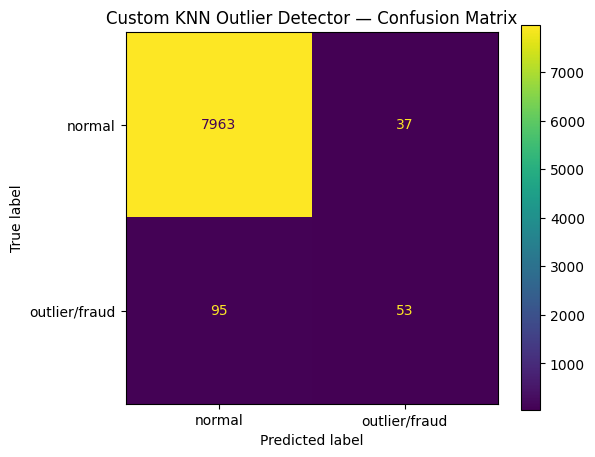

In [12]:
# Show the confusion matrix.
cm = confusion_matrix(y_eval, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["normal", "outlier/fraud"])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, values_format="d")
plt.title("Custom KNN Outlier Detector — Confusion Matrix")
plt.show()

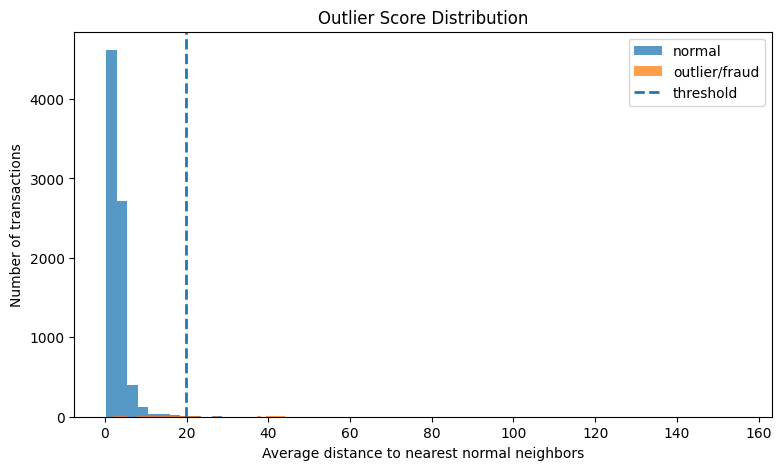

In [13]:
# Plot normal and fraud outlier scores.
normal_scores = results.loc[results["true_class"] == 0, "outlier_score"]
fraud_scores = results.loc[results["true_class"] == 1, "outlier_score"]

plt.figure(figsize=(9, 5))
plt.hist(normal_scores, bins=60, alpha=0.75, label="normal")
plt.hist(fraud_scores, bins=60, alpha=0.75, label="outlier/fraud")
plt.axvline(model.threshold_, linestyle="--", linewidth=2, label="threshold")
plt.title("Outlier Score Distribution")
plt.xlabel("Average distance to nearest normal neighbors")
plt.ylabel("Number of transactions")
plt.legend()
plt.show()

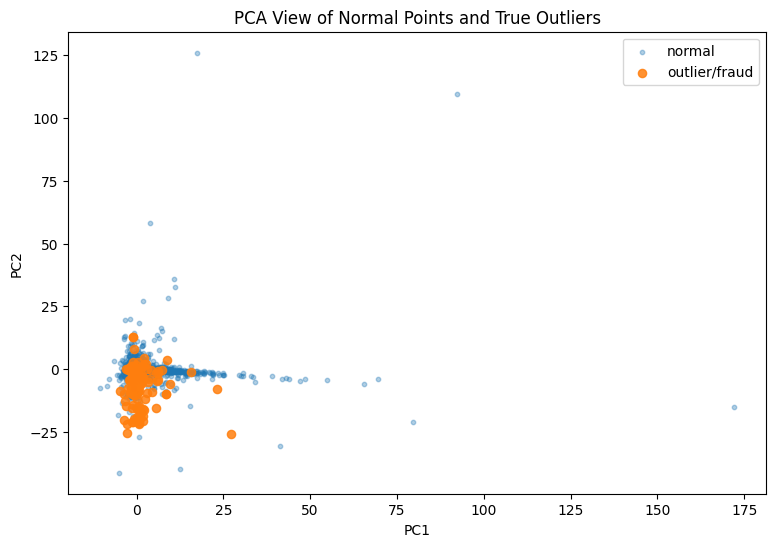

In [14]:
# Use PCA to plot the data in 2D.
scaled_for_plot = model.scaler_.transform(X_eval_raw)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
plot_points = pca.fit_transform(scaled_for_plot)

plot_df = pd.DataFrame({
    "PC1": plot_points[:, 0],
    "PC2": plot_points[:, 1],
    "true_class": y_eval.values,
    "predicted_outlier": preds,
    "outlier_score": scores,
})

plt.figure(figsize=(9, 6))
plt.scatter(
    plot_df.loc[plot_df["true_class"] == 0, "PC1"],
    plot_df.loc[plot_df["true_class"] == 0, "PC2"],
    s=10,
    alpha=0.35,
    label="normal",
)
plt.scatter(
    plot_df.loc[plot_df["true_class"] == 1, "PC1"],
    plot_df.loc[plot_df["true_class"] == 1, "PC2"],
    s=35,
    alpha=0.85,
    label="outlier/fraud",
)
plt.title("PCA View of Normal Points and True Outliers")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

In [15]:
# Show the most unusual transactions.
top_outliers = results.sort_values("outlier_score", ascending=False).head(15)

display_cols = ["Time", "Amount", "true_class", "outlier_score", "predicted_outlier"]
top_outliers[display_cols].reset_index(drop=True)

,Time,Amount,true_class,outlier_score,predicted_outlier
0,145283.0,10000.00,0,155.498755,1
1,142019.0,5964.95,0,147.672009,1
2,140878.0,538.71,0,115.593415,1
3,67676.0,6239.54,0,78.462519,1
4,68207.0,1.00,1,72.272872,1
5,68207.0,1.00,1,72.272872,1
6,149594.0,538.00,0,68.658221,1
7,18088.0,1218.89,1,67.461884,1
8,94362.0,1.00,1,63.407409,1
9,50257.0,5341.41,0,62.512495,1


In [16]:
# Compare the model with a simple z-score baseline.
amount_mean = normal_train["Amount"].mean()
amount_std = normal_train["Amount"].std()

z_scores_amount = (X_eval_raw["Amount"] - amount_mean) / amount_std
z_preds = (z_scores_amount.abs() > 3).astype(int)

print(classification_report(
    y_eval,
    z_preds,
    target_names=["normal", "outlier/fraud"],
    digits=4,
))

print("Z-score predicted outliers:", int(z_preds.sum()))

               precision    recall  f1-score   support

       normal     0.9820    0.9830    0.9825      8000
outlier/fraud     0.0286    0.0270    0.0278       148

     accuracy                         0.9656      8148
    macro avg     0.5053    0.5050    0.5051      8148
 weighted avg     0.9647    0.9656    0.9652      8148

Z-score predicted outliers: 140


In [17]:
# Save the final results in one summary.
summary = {
    "model": "CustomKNNOutlierDetector",
    "dataset": "Kaggle: mlg-ulb/creditcardfraud",
    "training_normal_rows": len(normal_train),
    "evaluation_rows": len(X_eval_raw),
    "real_outliers_in_evaluation": int(y_eval.sum()),
    "predicted_outliers": int(preds.sum()),
    "threshold": round(float(model.threshold_), 6),
    "roc_auc": round(float(roc_auc), 4),
    "pr_auc": round(float(pr_auc), 4),
}

summary

{'model': 'CustomKNNOutlierDetector',
 'dataset': 'Kaggle: mlg-ulb/creditcardfraud',
 'training_normal_rows': 8000,
 'evaluation_rows': 8148,
 'real_outliers_in_evaluation': 148,
 'predicted_outliers': 90,
 'threshold': 19.848785,
 'roc_auc': 0.9476,
 'pr_auc': 0.4714}

## Метод 2 Local Outlier Factor (LOF)


In [18]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(
    n_neighbors=15,
    contamination=0.005, 
    novelty=True,
    n_jobs=-1,
)
lof.fit(model.scaler_.transform(normal_train)) 

lof_scores = -lof.score_samples(model.scaler_.transform(X_eval_raw))
lof_preds  = (lof.predict(model.scaler_.transform(X_eval_raw)) == -1).astype(int)

lof_roc = roc_auc_score(y_eval, lof_scores)
lof_pr  = average_precision_score(y_eval, lof_scores)

print(classification_report(y_eval, lof_preds,
      target_names=['normal', 'outlier/fraud'], digits=4))
print('LOF ROC AUC:', round(float(lof_roc), 4))
print('LOF PR  AUC:', round(float(lof_pr),  4))


               precision    recall  f1-score   support

       normal     0.9947    0.9945    0.9946      8000
outlier/fraud     0.7067    0.7162    0.7114       148

     accuracy                         0.9894      8148
    macro avg     0.8507    0.8554    0.8530      8148
 weighted avg     0.9895    0.9894    0.9895      8148

LOF ROC AUC: 0.9244
LOF PR  AUC: 0.6997


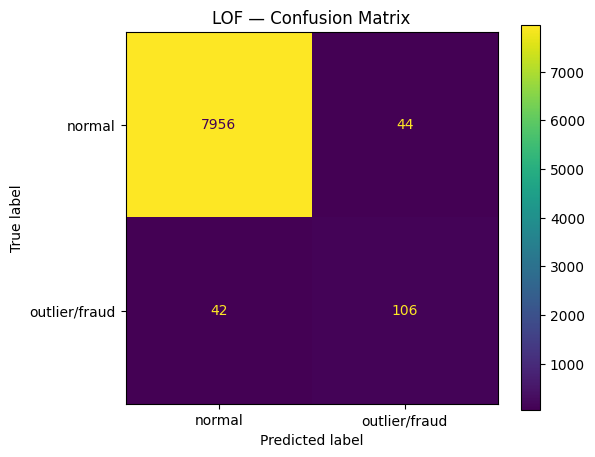

In [19]:
cm_lof = confusion_matrix(y_eval, lof_preds)
disp = ConfusionMatrixDisplay(cm_lof, display_labels=['normal', 'outlier/fraud'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, values_format='d')
plt.title('LOF — Confusion Matrix')
plt.show()


## Метод 3 Расширенный Z-score (многомерный)


In [20]:
# Считаем mean и std по обучающим нормальным данным
train_mean = normal_train.mean()
train_std  = normal_train.std().replace(0, 1e-9)   # защита от деления на 0

# Для каждой точки берём максимальный |Z| среди всех признаков
z_matrix = (X_eval_raw - train_mean).abs() / train_std
z_scores_multi = z_matrix.max(axis=1).values

# Порог — 99.5-й перцентиль по нормальным точкам (аналогично KNN)
z_train_scores = ((normal_train - train_mean).abs() / train_std).max(axis=1).values
z_threshold    = np.quantile(z_train_scores, 1 - 0.005)
z_preds_multi  = (z_scores_multi > z_threshold).astype(int)

z_roc = roc_auc_score(y_eval, z_scores_multi)
z_pr  = average_precision_score(y_eval, z_scores_multi)

print(f'Z-score threshold (99.5p): {z_threshold:.4f}')
print()
print(classification_report(y_eval, z_preds_multi,
      target_names=['normal', 'outlier/fraud'], digits=4))
print('Z-score ROC AUC:', round(float(z_roc), 4))
print('Z-score PR  AUC:', round(float(z_pr),  4))


Z-score threshold (99.5p): 12.4258

               precision    recall  f1-score   support

       normal     0.9892    0.9955    0.9923      8000
outlier/fraud     0.6289    0.4122    0.4980       148

     accuracy                         0.9849      8148
    macro avg     0.8090    0.7038    0.7451      8148
 weighted avg     0.9826    0.9849    0.9834      8148

Z-score ROC AUC: 0.9368
Z-score PR  AUC: 0.4979


## Метод 4 Автоэнкодер (Autoencoder)


In [21]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── Архитектура: encoder 30→16→8, decoder 8→16→30 ──────────────────────
class Autoencoder(nn.Module):
    def __init__(self, n_features: int, bottleneck: int = 8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 16), nn.ReLU(),
            nn.Linear(16, bottleneck), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, 16), nn.ReLU(),
            nn.Linear(16, n_features),
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))


# ── Данные (используем тот же RobustScaler от KNN-модели) ───────────────
X_train_sc = torch.tensor(
    model.scaler_.transform(normal_train), dtype=torch.float32
)
X_eval_sc = torch.tensor(
    model.scaler_.transform(X_eval_raw), dtype=torch.float32
)

loader = DataLoader(
    TensorDataset(X_train_sc),
    batch_size=256, shuffle=True
)

# ── Обучение ─────────────────────────────────────────────────────────────
ae = Autoencoder(n_features=X_train_sc.shape[1]).to(DEVICE)
optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
criterion = nn.MSELoss()

ae.train()
for epoch in range(30):
    total_loss = 0
    for (batch,) in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(ae(batch), batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch)
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:02d} | loss: {total_loss / len(X_train_sc):.6f}')

# ── Вычисляем reconstruction error как anomaly score ─────────────────────
ae.eval()
with torch.no_grad():
    X_eval_dev = X_eval_sc.to(DEVICE)
    recon = ae(X_eval_dev).cpu()
    ae_scores = ((X_eval_sc - recon) ** 2).mean(dim=1).numpy()

# Порог — 99.5-й перцентиль на обучающих данных
with torch.no_grad():
    recon_train = ae(X_train_sc.to(DEVICE)).cpu()
    train_recon_err = ((X_train_sc - recon_train) ** 2).mean(dim=1).numpy()

ae_threshold = np.quantile(train_recon_err, 1 - 0.005)
ae_preds = (ae_scores > ae_threshold).astype(int)

ae_roc = roc_auc_score(y_eval, ae_scores)
ae_pr  = average_precision_score(y_eval, ae_scores)

print(f'AE threshold (99.5p): {ae_threshold:.6f}')
print()
print(classification_report(y_eval, ae_preds,
      target_names=['normal', 'outlier/fraud'], digits=4))
print('AE ROC AUC:', round(float(ae_roc), 4))
print('AE PR  AUC:', round(float(ae_pr),  4))


Epoch 10 | loss: 0.980435
Epoch 20 | loss: 0.733428
Epoch 30 | loss: 0.610274
AE threshold (99.5p): 7.676199

               precision    recall  f1-score   support

       normal     0.9915    0.9946    0.9931      8000
outlier/fraud     0.6504    0.5405    0.5904       148

     accuracy                         0.9864      8148
    macro avg     0.8210    0.7676    0.7917      8148
 weighted avg     0.9853    0.9864    0.9858      8148

AE ROC AUC: 0.9445
AE PR  AUC: 0.5575


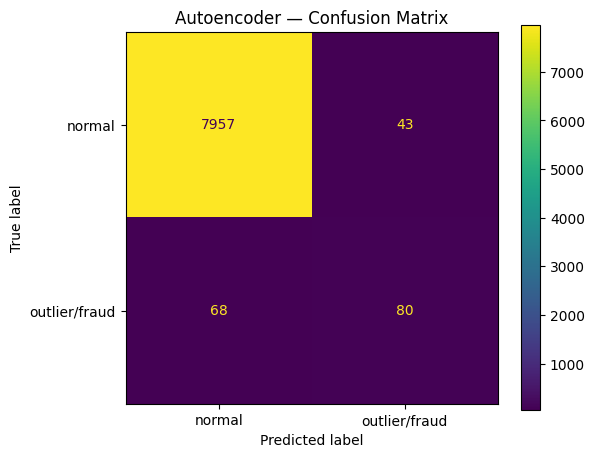

In [22]:
cm_ae = confusion_matrix(y_eval, ae_preds)
disp = ConfusionMatrixDisplay(cm_ae, display_labels=['normal', 'outlier/fraud'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, values_format='d')
plt.title('Autoencoder — Confusion Matrix')
plt.show()


## Итоговое сравнение четырёх методов


                 ROC AUC  PR AUC
Method                          
CustomKNN         0.9476  0.4714
LOF               0.9244  0.6997
Z-score (multi)   0.9368  0.4979
Autoencoder       0.9445  0.5575


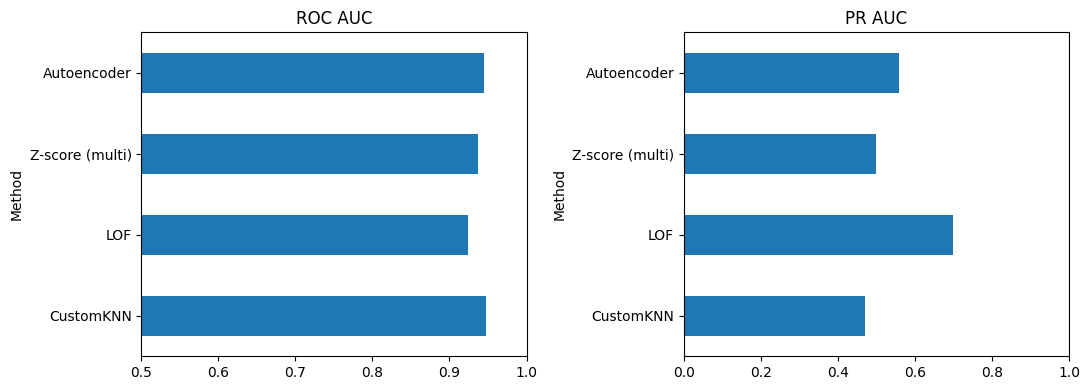

In [23]:
methods = ['CustomKNN', 'LOF', 'Z-score (multi)', 'Autoencoder']
roc_aucs = [roc_auc, lof_roc, z_roc, ae_roc]
pr_aucs  = [pr_auc,  lof_pr,  z_pr,  ae_pr]

comparison_df = pd.DataFrame({
    'Method':  methods,
    'ROC AUC': [round(v, 4) for v in roc_aucs],
    'PR AUC':  [round(v, 4) for v in pr_aucs],
}).set_index('Method')

print(comparison_df.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
comparison_df['ROC AUC'].plot(kind='barh', ax=axes[0], title='ROC AUC', xlim=(0.5, 1.0))
comparison_df['PR AUC'].plot(kind='barh', ax=axes[1], title='PR AUC',  xlim=(0.0, 1.0))
plt.tight_layout()
plt.show()
